In [1]:
""""
Copyright (C) 2025 ETH Zurich, Stefan J.P. Chrin, Gregory Landrum, Sereina Riniker
"""

import sys
sys.path.append("../../../SRC/")

### Define Parameters and preprocess the data

In [2]:
from DDG_ANALYSIS.B_PREPROCESS import preprocess

# --- Dictionary mapping file names to their json file paths ---
files = {
    "MIN": "../../../A_MODELS/FUSION/DDG/A_OUTPUT/ddG_ridge_LOO_pred&error_MIN_MET_OPLS.json",
    "MAX": "../../../A_MODELS/FUSION/DDG/A_OUTPUT/ddG_ridge_LOO_pred&error_MAX_MET_OPLS.json",
    "AVG": "../../../A_MODELS/FUSION/DDG/A_OUTPUT/ddG_ridge_LOO_pred&error_AVG_MET_OPLS.json",
    "MET": "../../../A_MODELS/Z_META/DDG/RANDOM/ddG_ridge_LOO_pred&error.json",
    "OPLS": "../../../A_MODELS/FEP/DDG/OPLS/OPLS_RANDOM_ddG_FROM_FEP_GRAPH_pred&error.json"
}

DISPLAY_ORDER = ["OPLS","MET","AVG","MAX","MIN"]
DISPLAY_ORDER.reverse()
ALPHA = 0.01
TARGETS_TO_SKIP = ("galectin","thrombin","p2")
METRICS = ["rmse", "kendalls_tau", "window_tau", "slope_diff"]

results_all, bad_splits = preprocess(files, TARGETS_TO_SKIP)


No splits removed.


In [3]:
# Check which splits have constant labels or predictions
print(bad_splits)

{}


### Friedman ANOVA

In [4]:
from DDG_ANALYSIS.C_FRIEDMAN_ANOVA import run_friedman

friedman_results = run_friedman(results_all, METRICS, TARGETS_TO_SKIP=TARGETS_TO_SKIP)
print(friedman_results)

{'rmse': {'bace': {'statistic': 275.93600000000015, 'p_value': 1.6756130267740655e-58}, 'cdk2': {'statistic': 133.8050251256281, 'p_value': 5.977145296227077e-28}, 'cdk8': {'statistic': 267.52800000000025, 'p_value': 1.0879446871910784e-56}, 'cmet': {'statistic': 110.05600000000004, 'p_value': 7.080246366580505e-23}, 'eg5': {'statistic': 208.42399999999998, 'p_value': 5.799208565267336e-44}, 'hif2a': {'statistic': 203.89599999999996, 'p_value': 5.4596408277125075e-43}, 'hunt': {'statistic': 189.31999999999994, 'p_value': 7.420184766493984e-40}, 'jnk1': {'statistic': 113.29292929292937, 'p_value': 1.4438619202465314e-23}, 'mcl1': {'statistic': 317.4720000000002, 'p_value': 1.8417637699041398e-67}, 'p38': {'statistic': 150.27999999999997, 'p_value': 1.7730684509608957e-31}, 'pde10': {'statistic': 324.384, 'p_value': 5.937563347222927e-69}, 'pde2': {'statistic': 237.23694779116468, 'p_value': 3.6513174501576984e-50}, 'pfkfb3': {'statistic': 268.77599999999984, 'p_value': 5.856165459283091

### Wilcoxon test

In [5]:
from DDG_ANALYSIS.D_WILCOXON import compute_wilcox_posthoc
wilcox_posthoc_results = compute_wilcox_posthoc(results_all, metrics=METRICS, targets_to_skip=TARGETS_TO_SKIP)


### Significance plot

rmse significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DDG/CONSENSUS_FEP/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


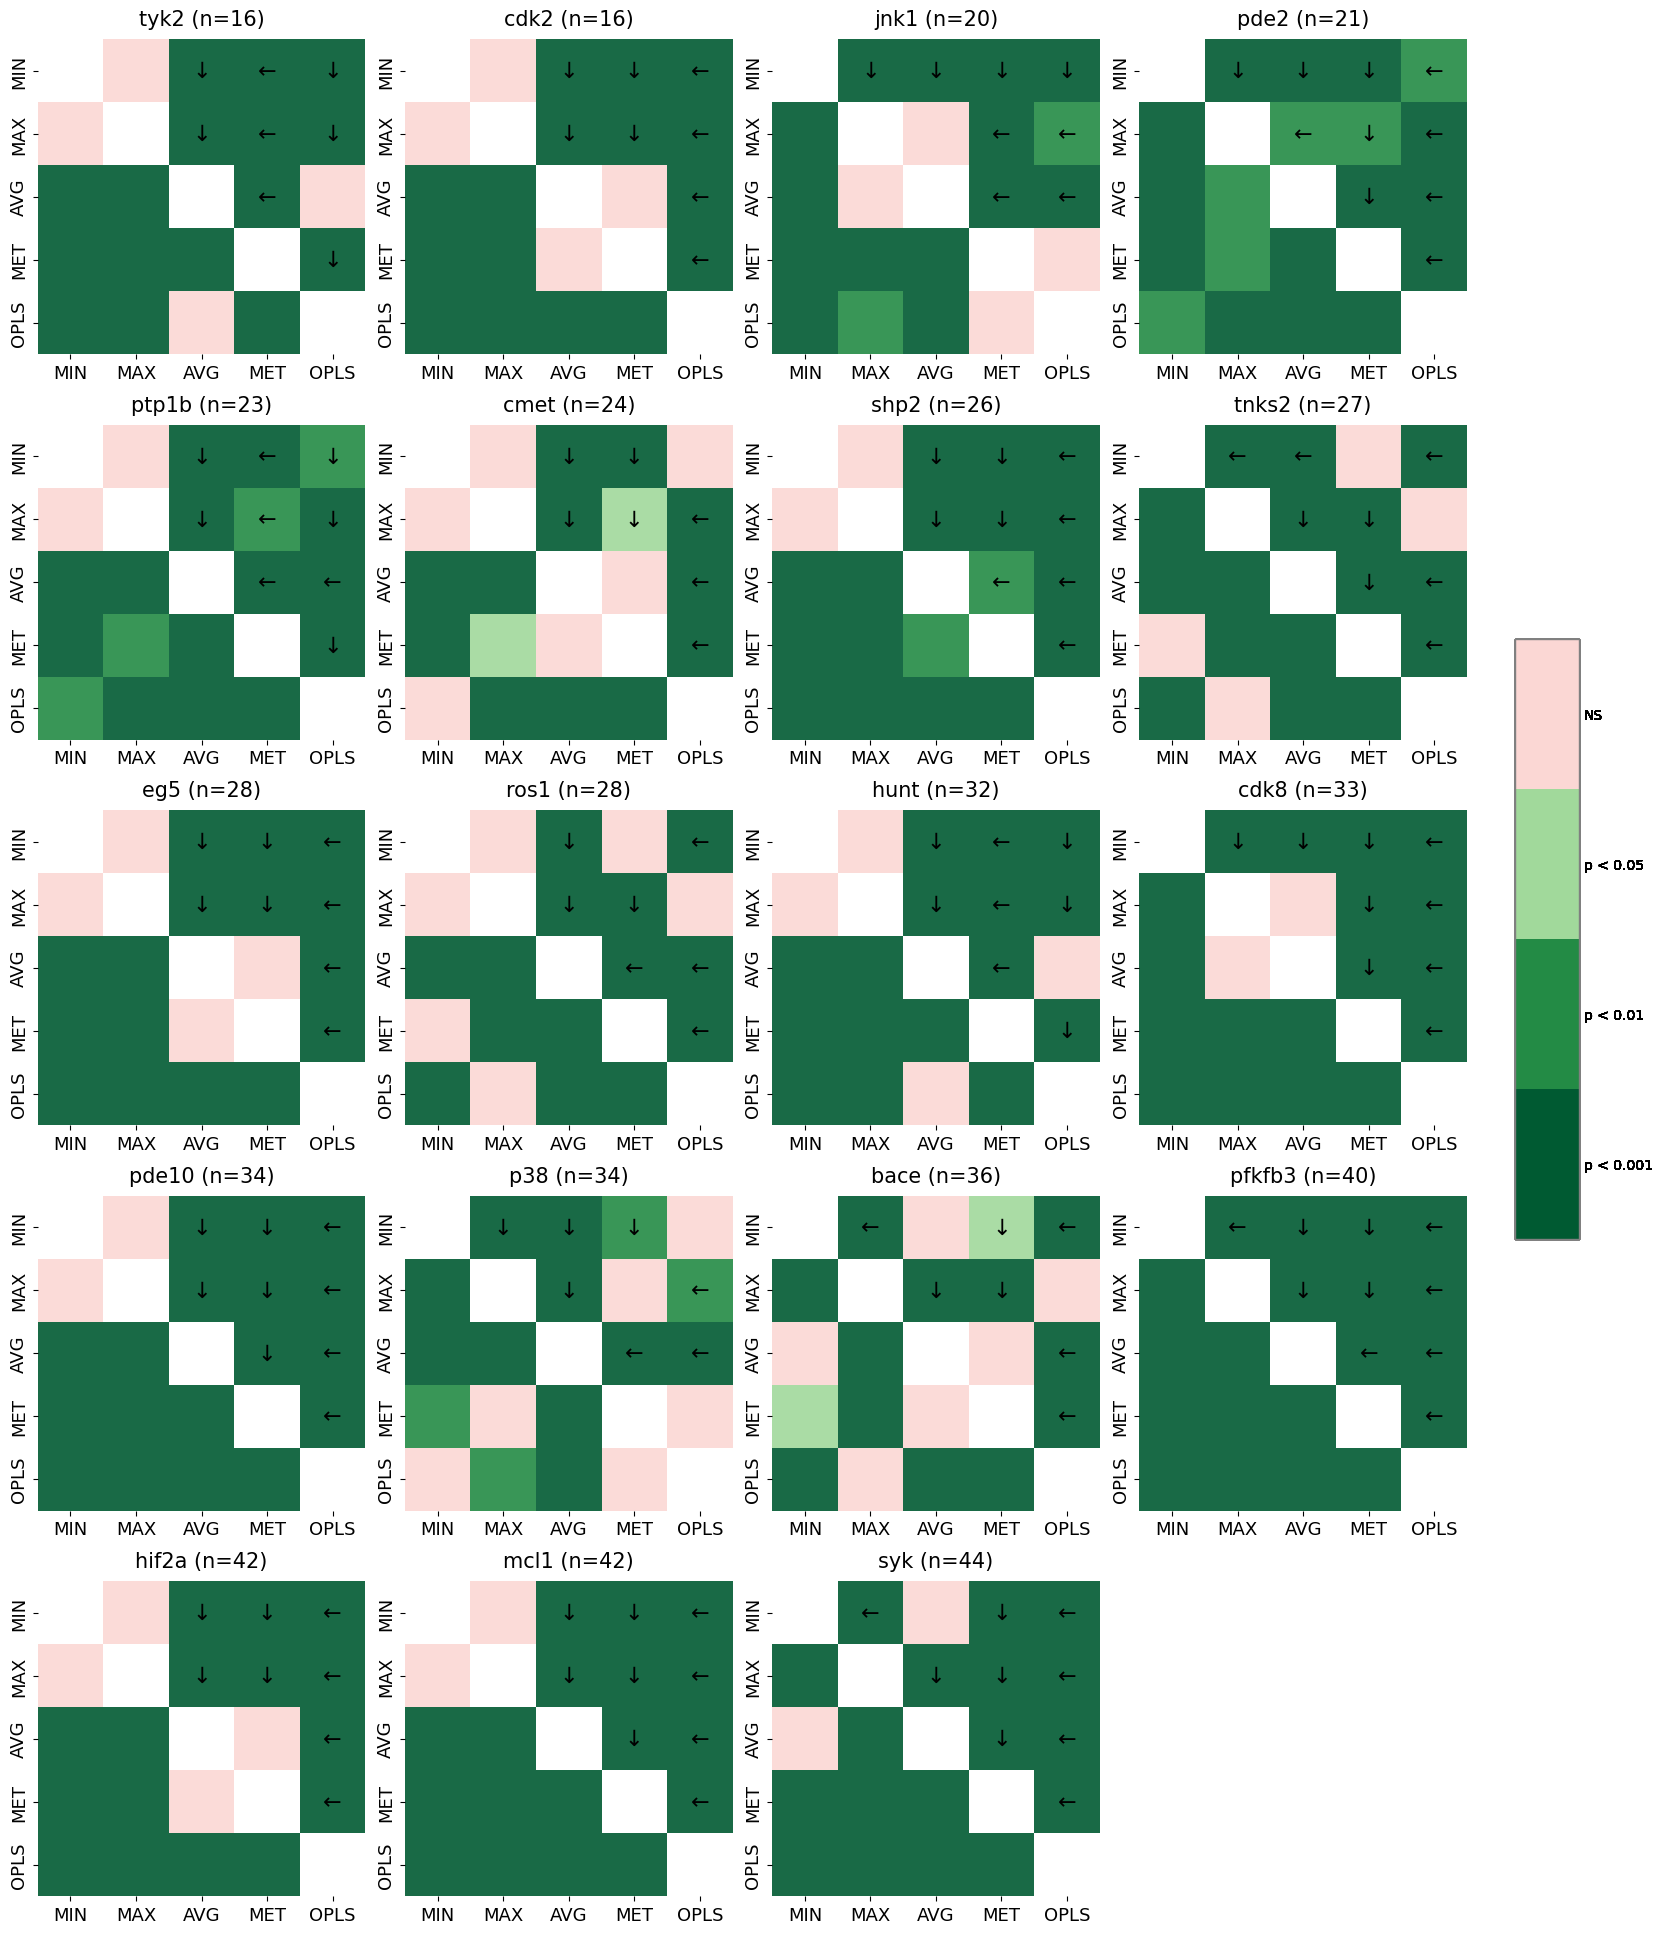

kendalls_tau significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DDG/CONSENSUS_FEP/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


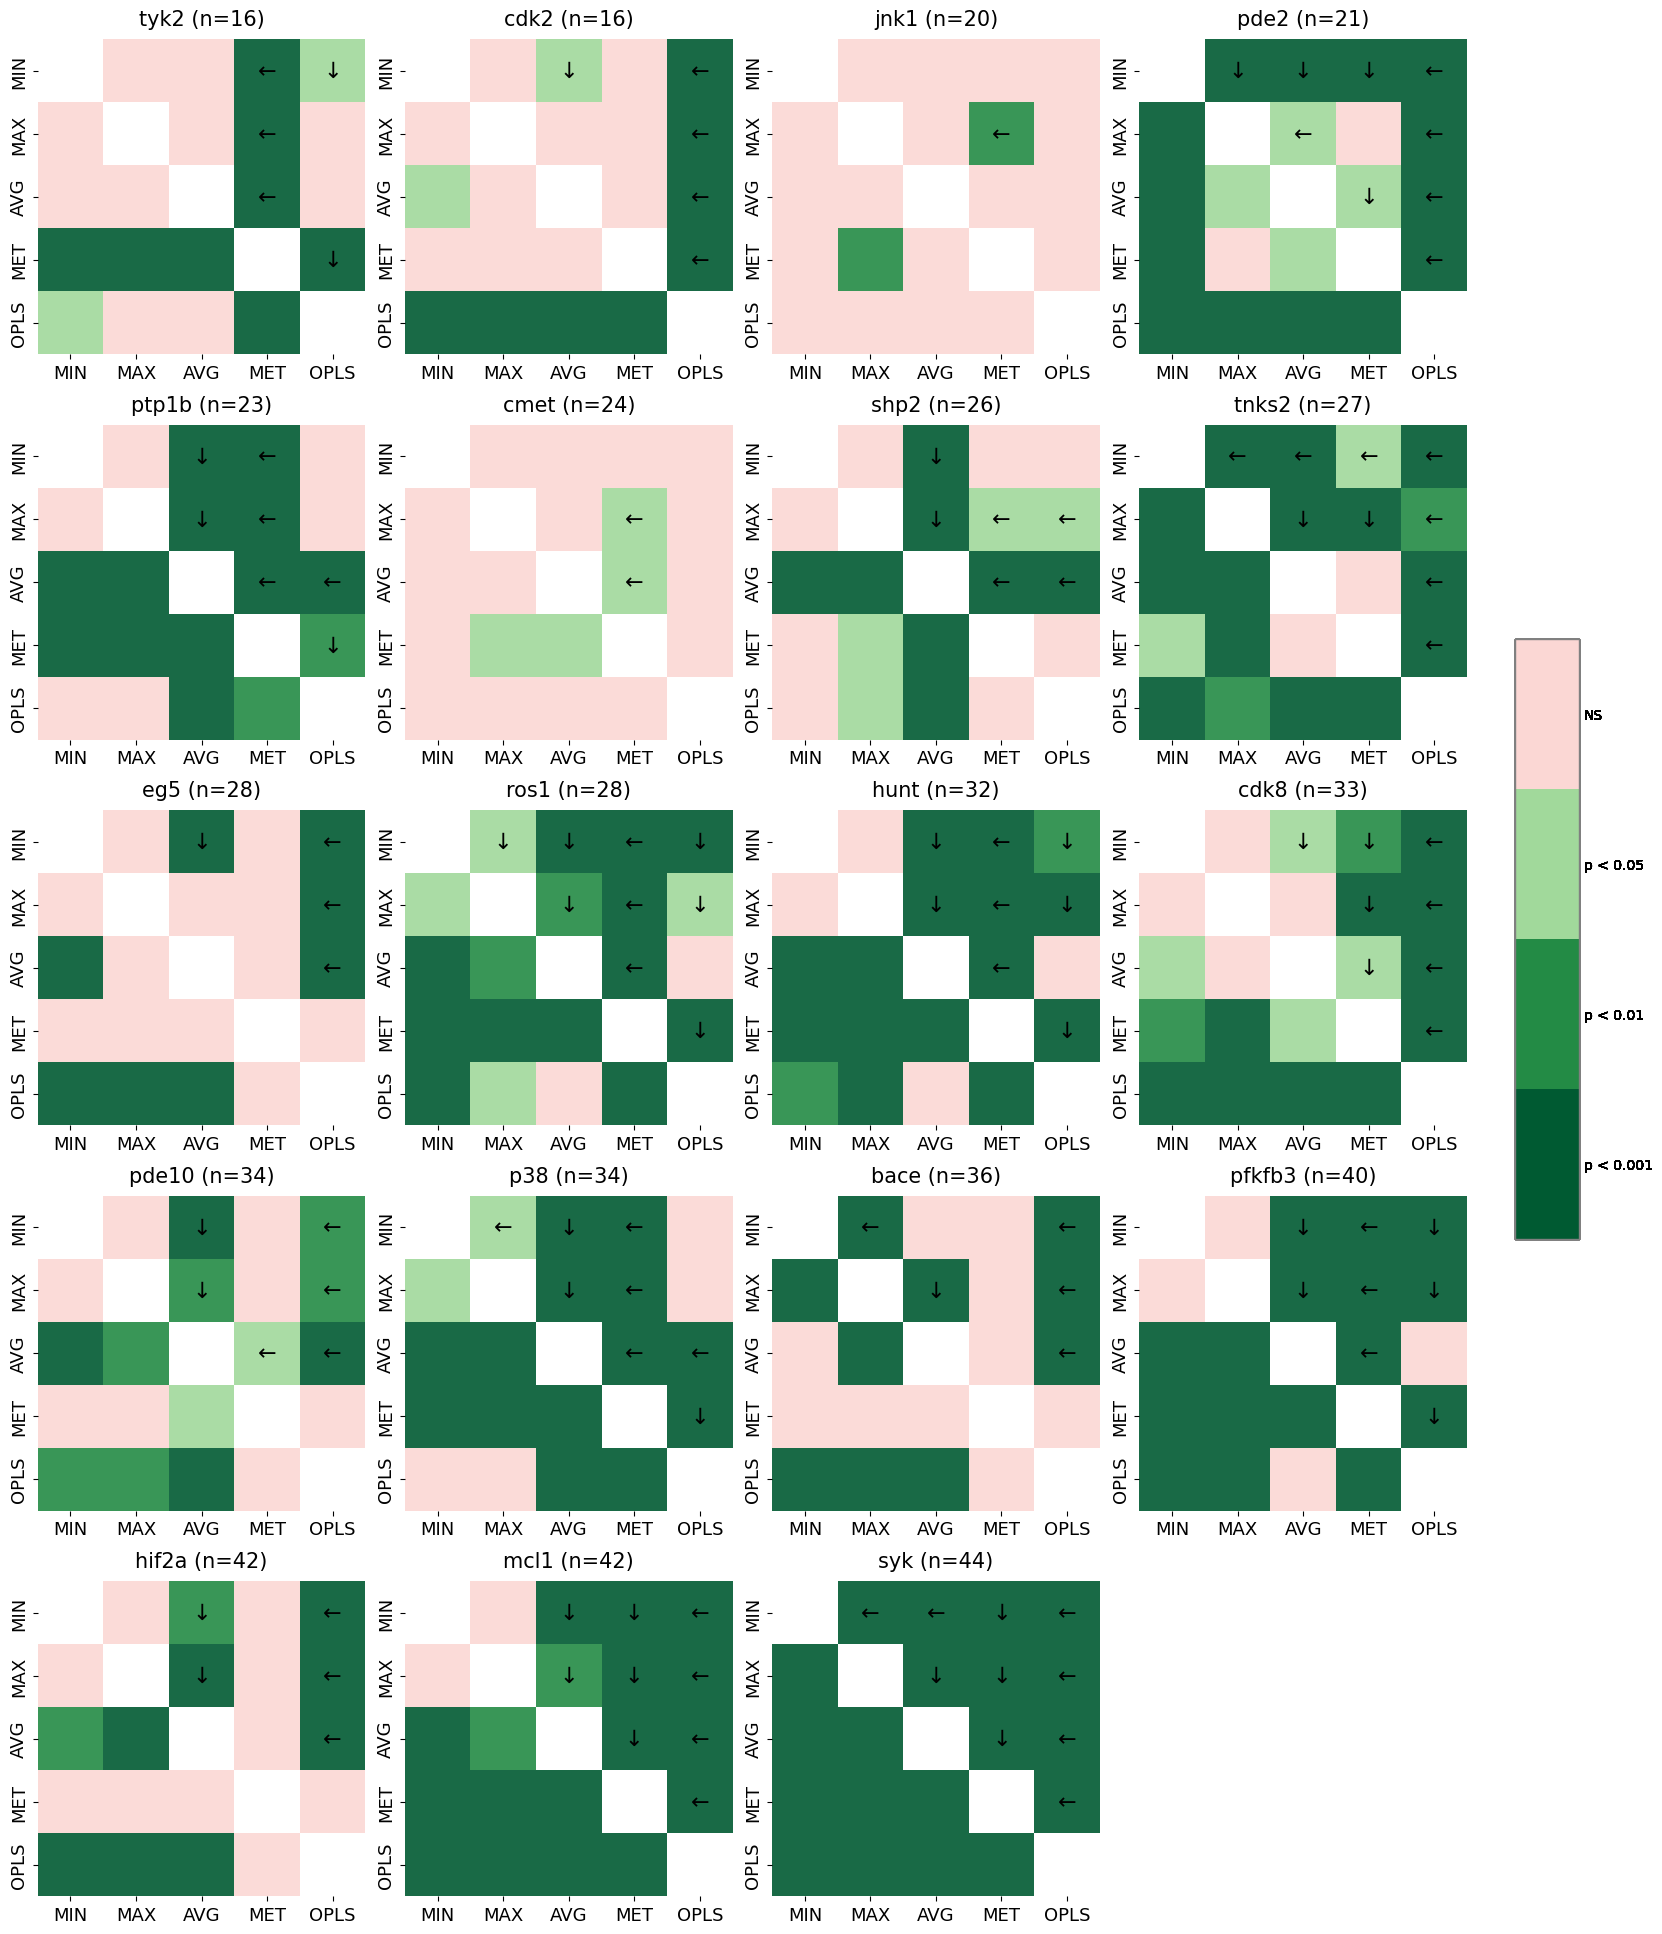

window_tau significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DDG/CONSENSUS_FEP/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


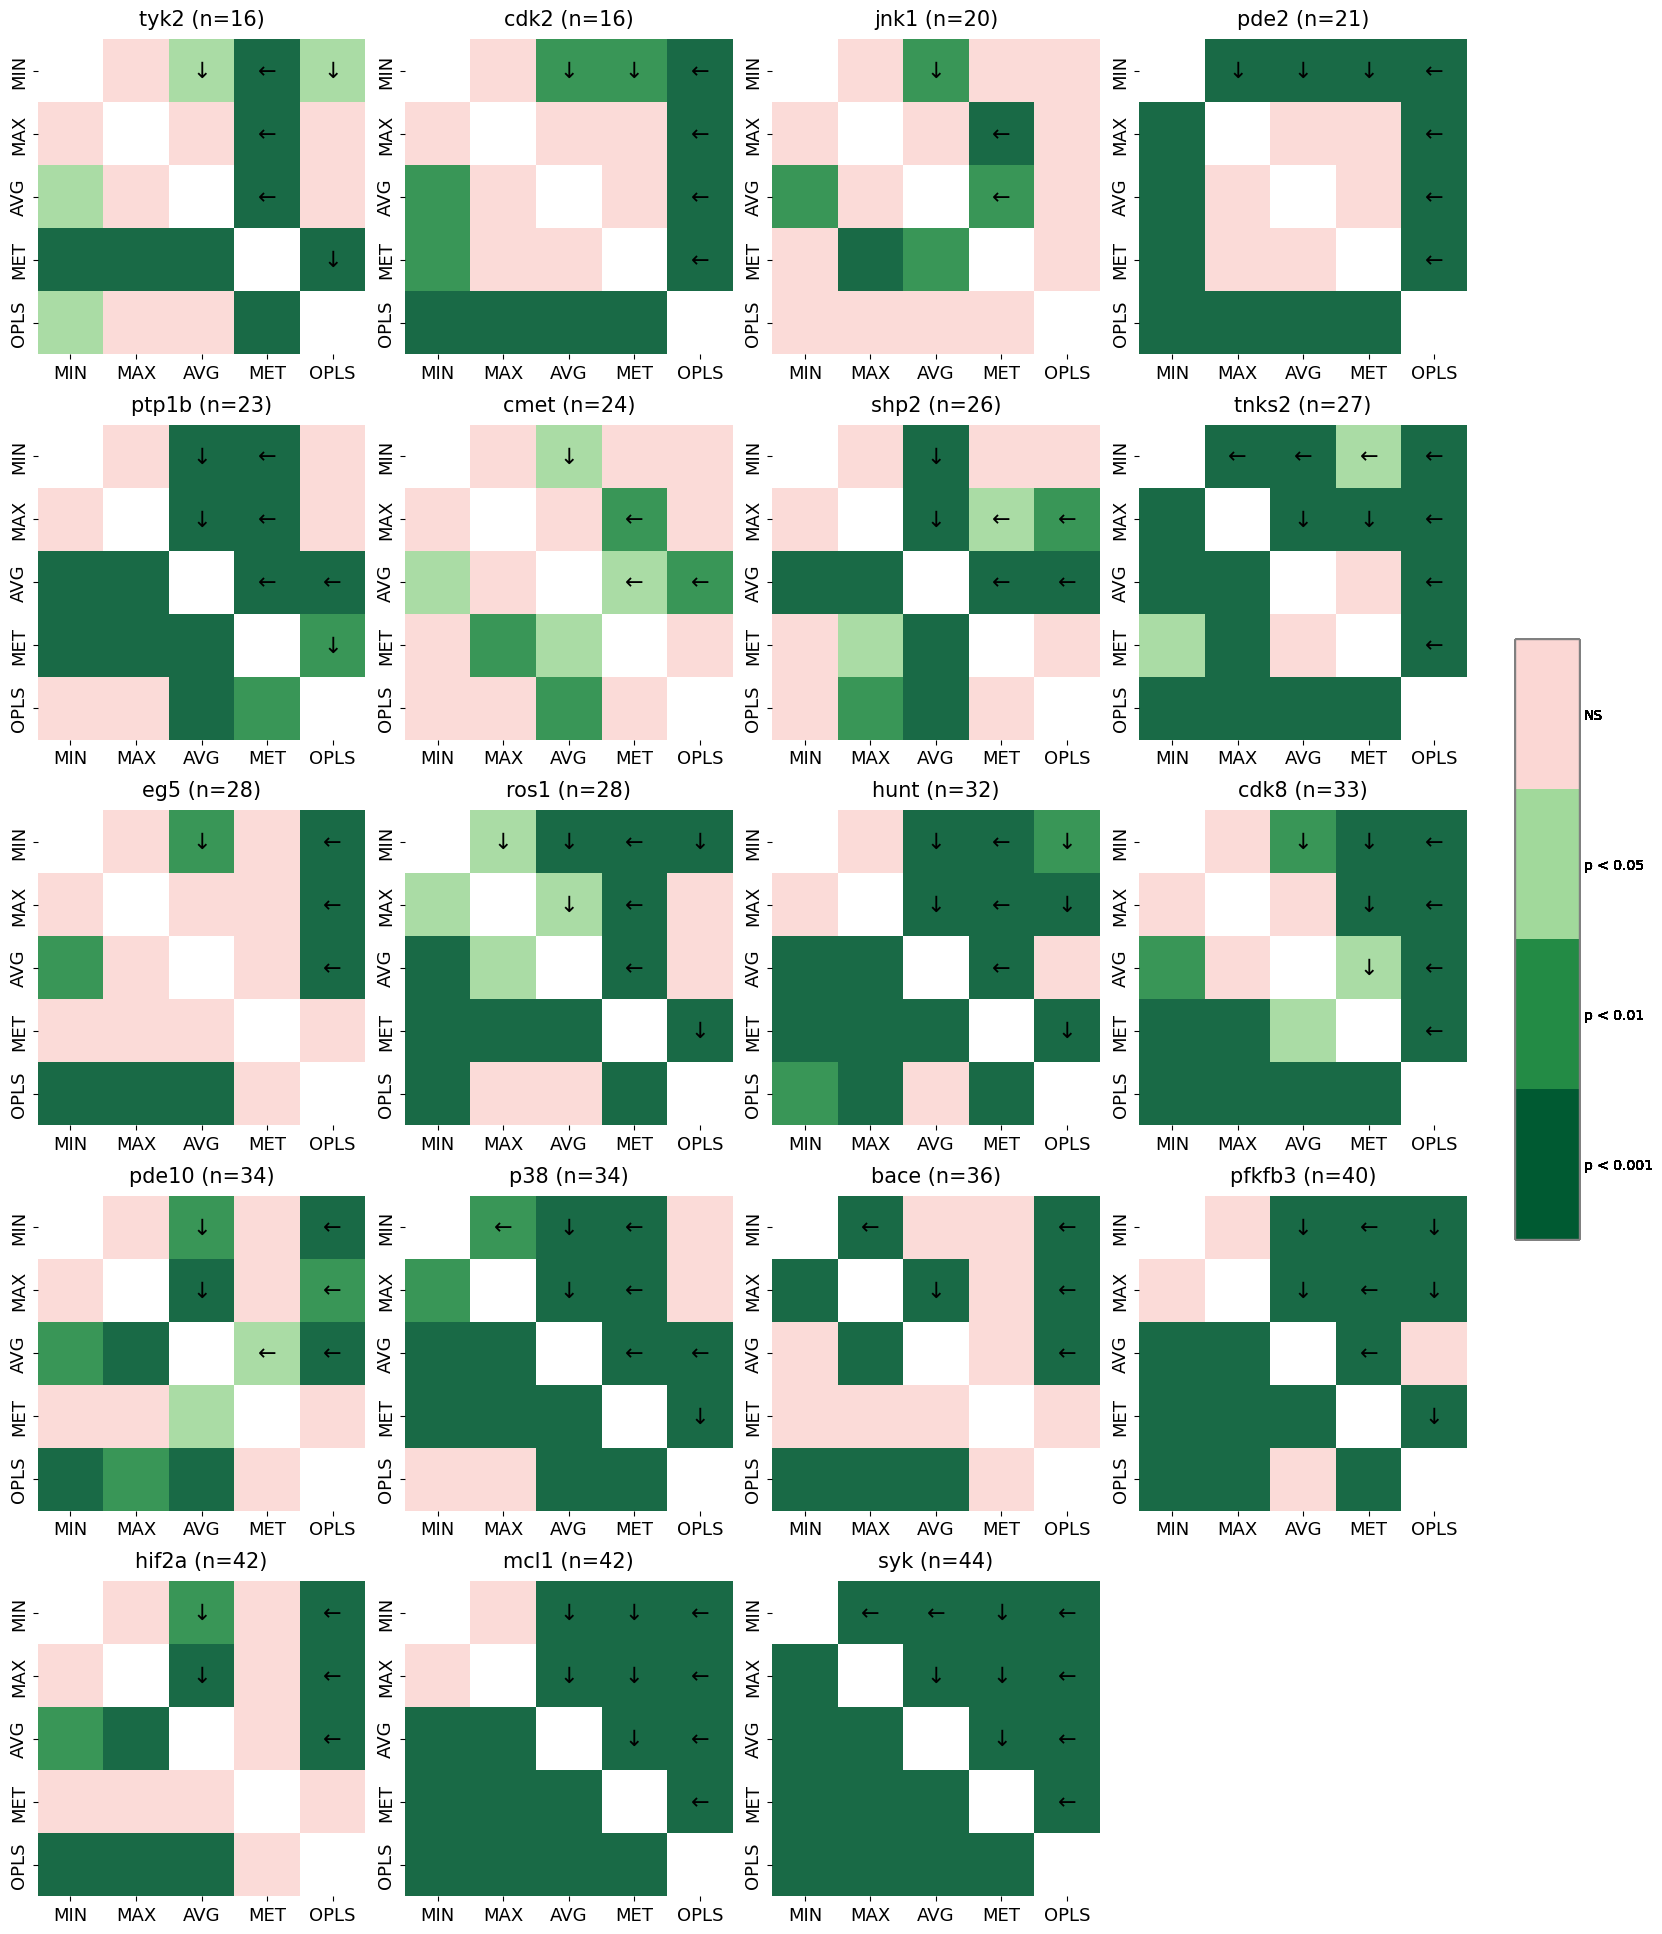

slope_diff significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DDG/CONSENSUS_FEP/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


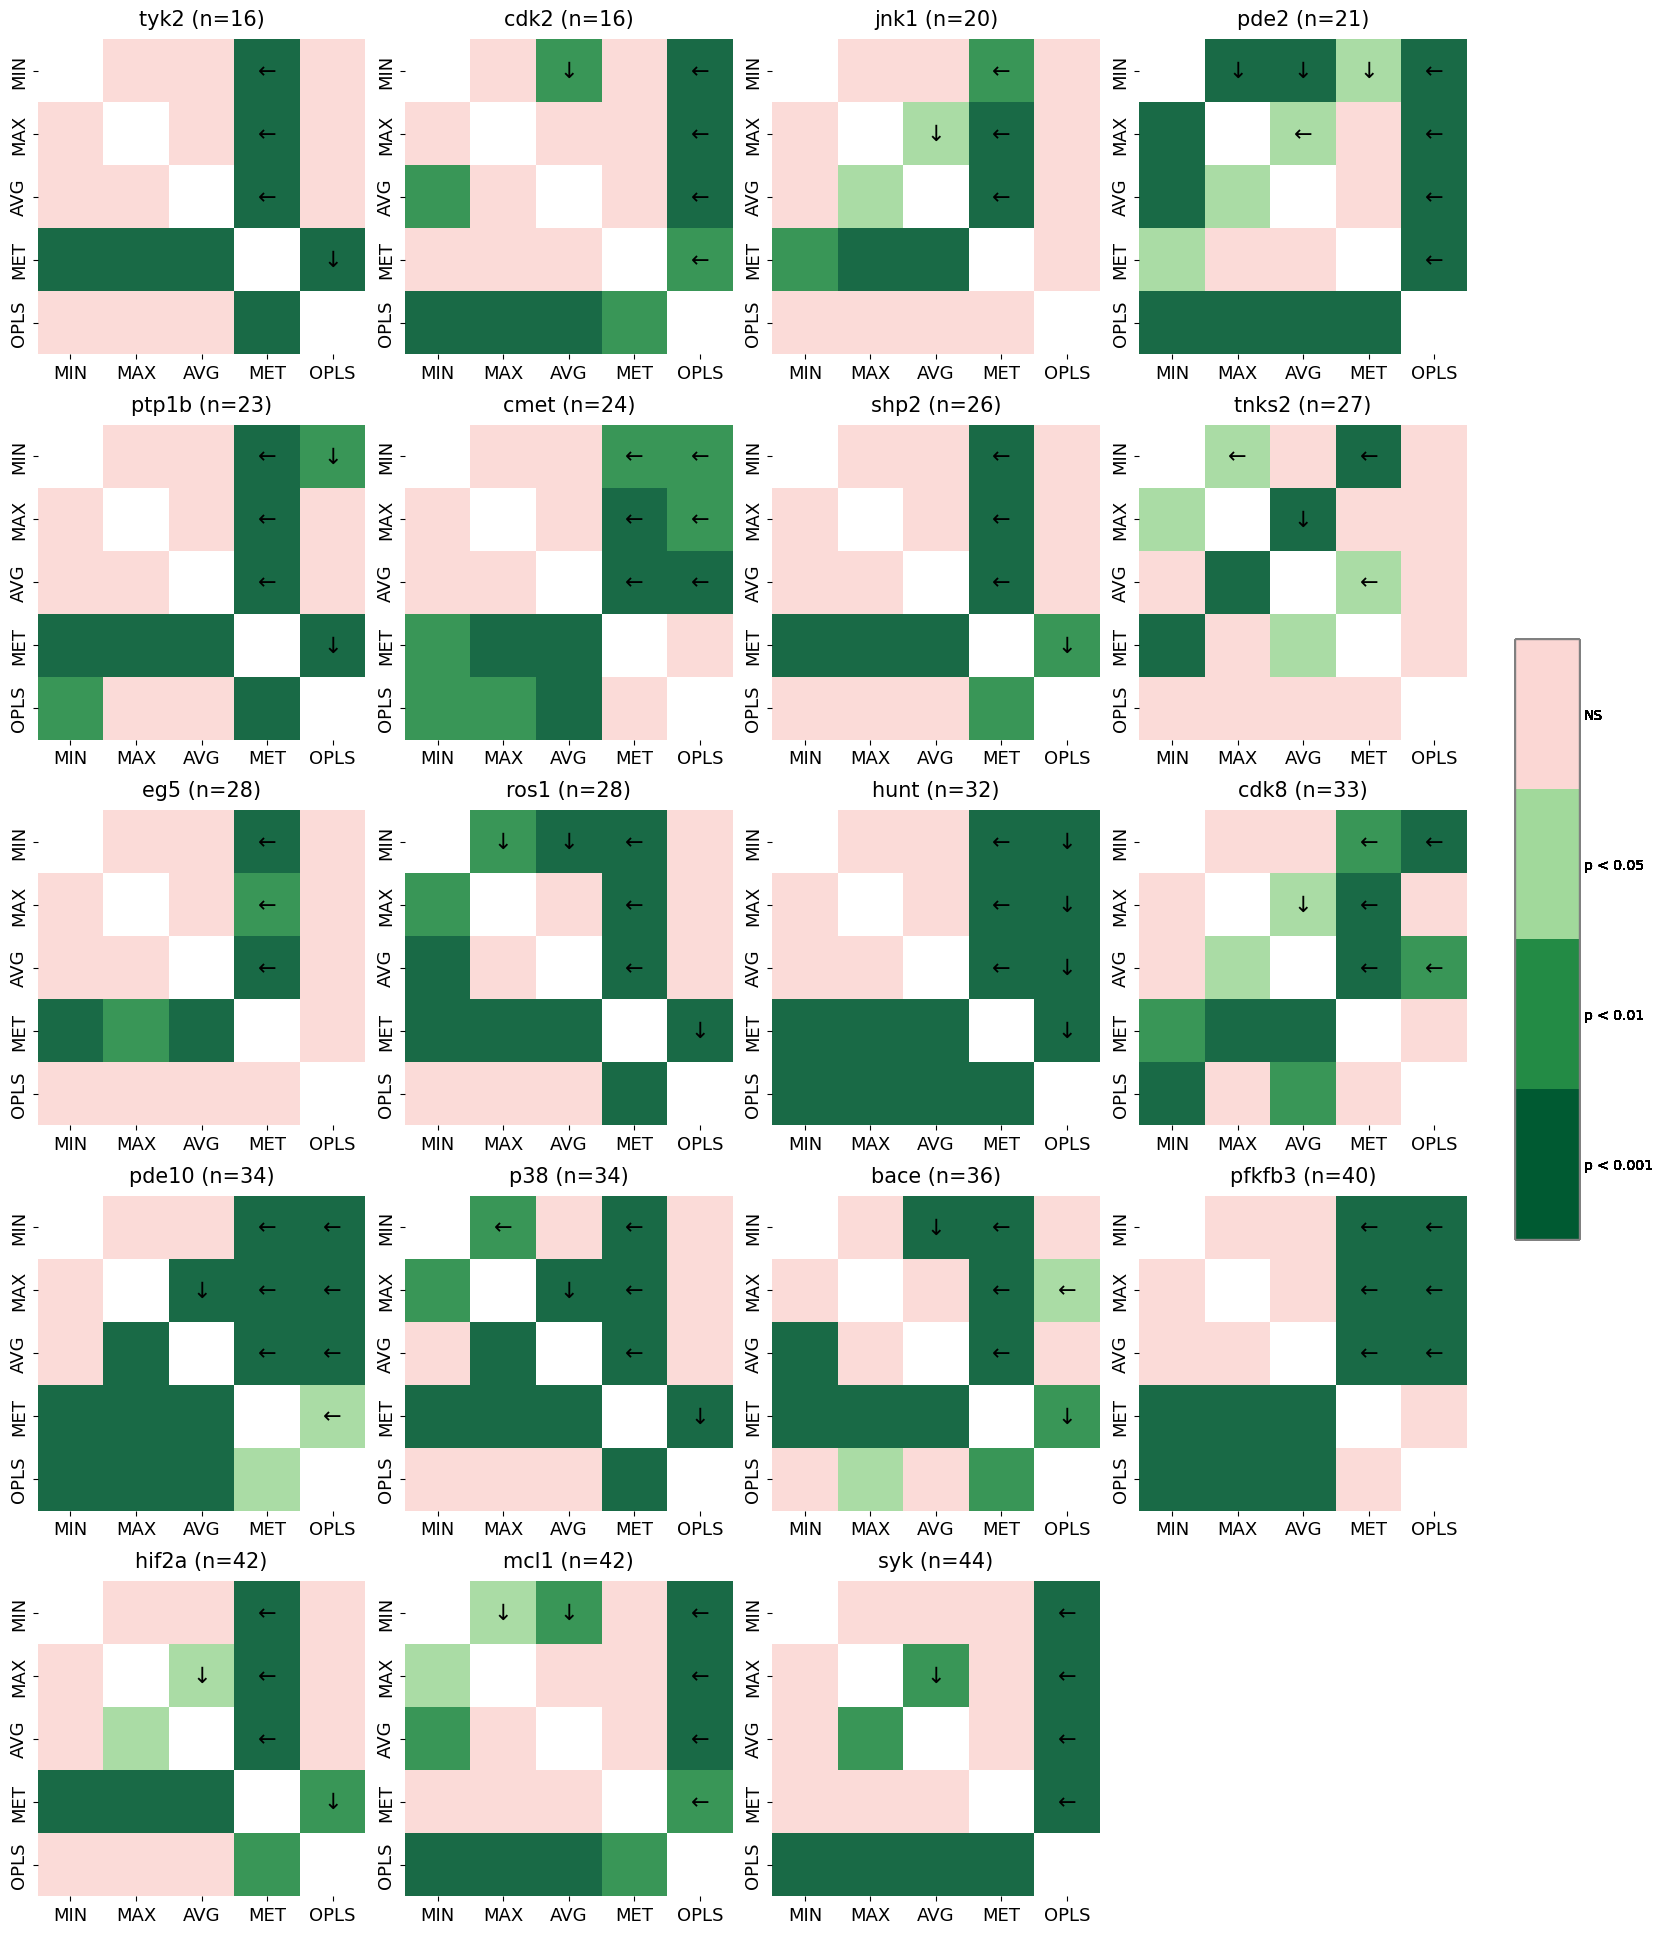

In [6]:
from DDG_ANALYSIS.D_WILCOXON import sign_plot
sign_plot(
    results_all,
    wilcox_posthoc_results,
    DISPLAY_ORDER,
    target_counts_path= "../../../0_DATA/N_COMPOUNDS_PER_TARGET.json",
    metrics=METRICS,
    targets_to_skip=TARGETS_TO_SKIP,
    n_cols=4,
    arrow_threshold=0.05, # This is the p value for an arrow to show, should be in accordance with the legend (green -> has an arrow)
    alpha=0.9, # this alpha is how seethrough plot is, not to be mixed up with ALPHA (p value)
)

### Effect size & Significance (Based on wilcoxon)

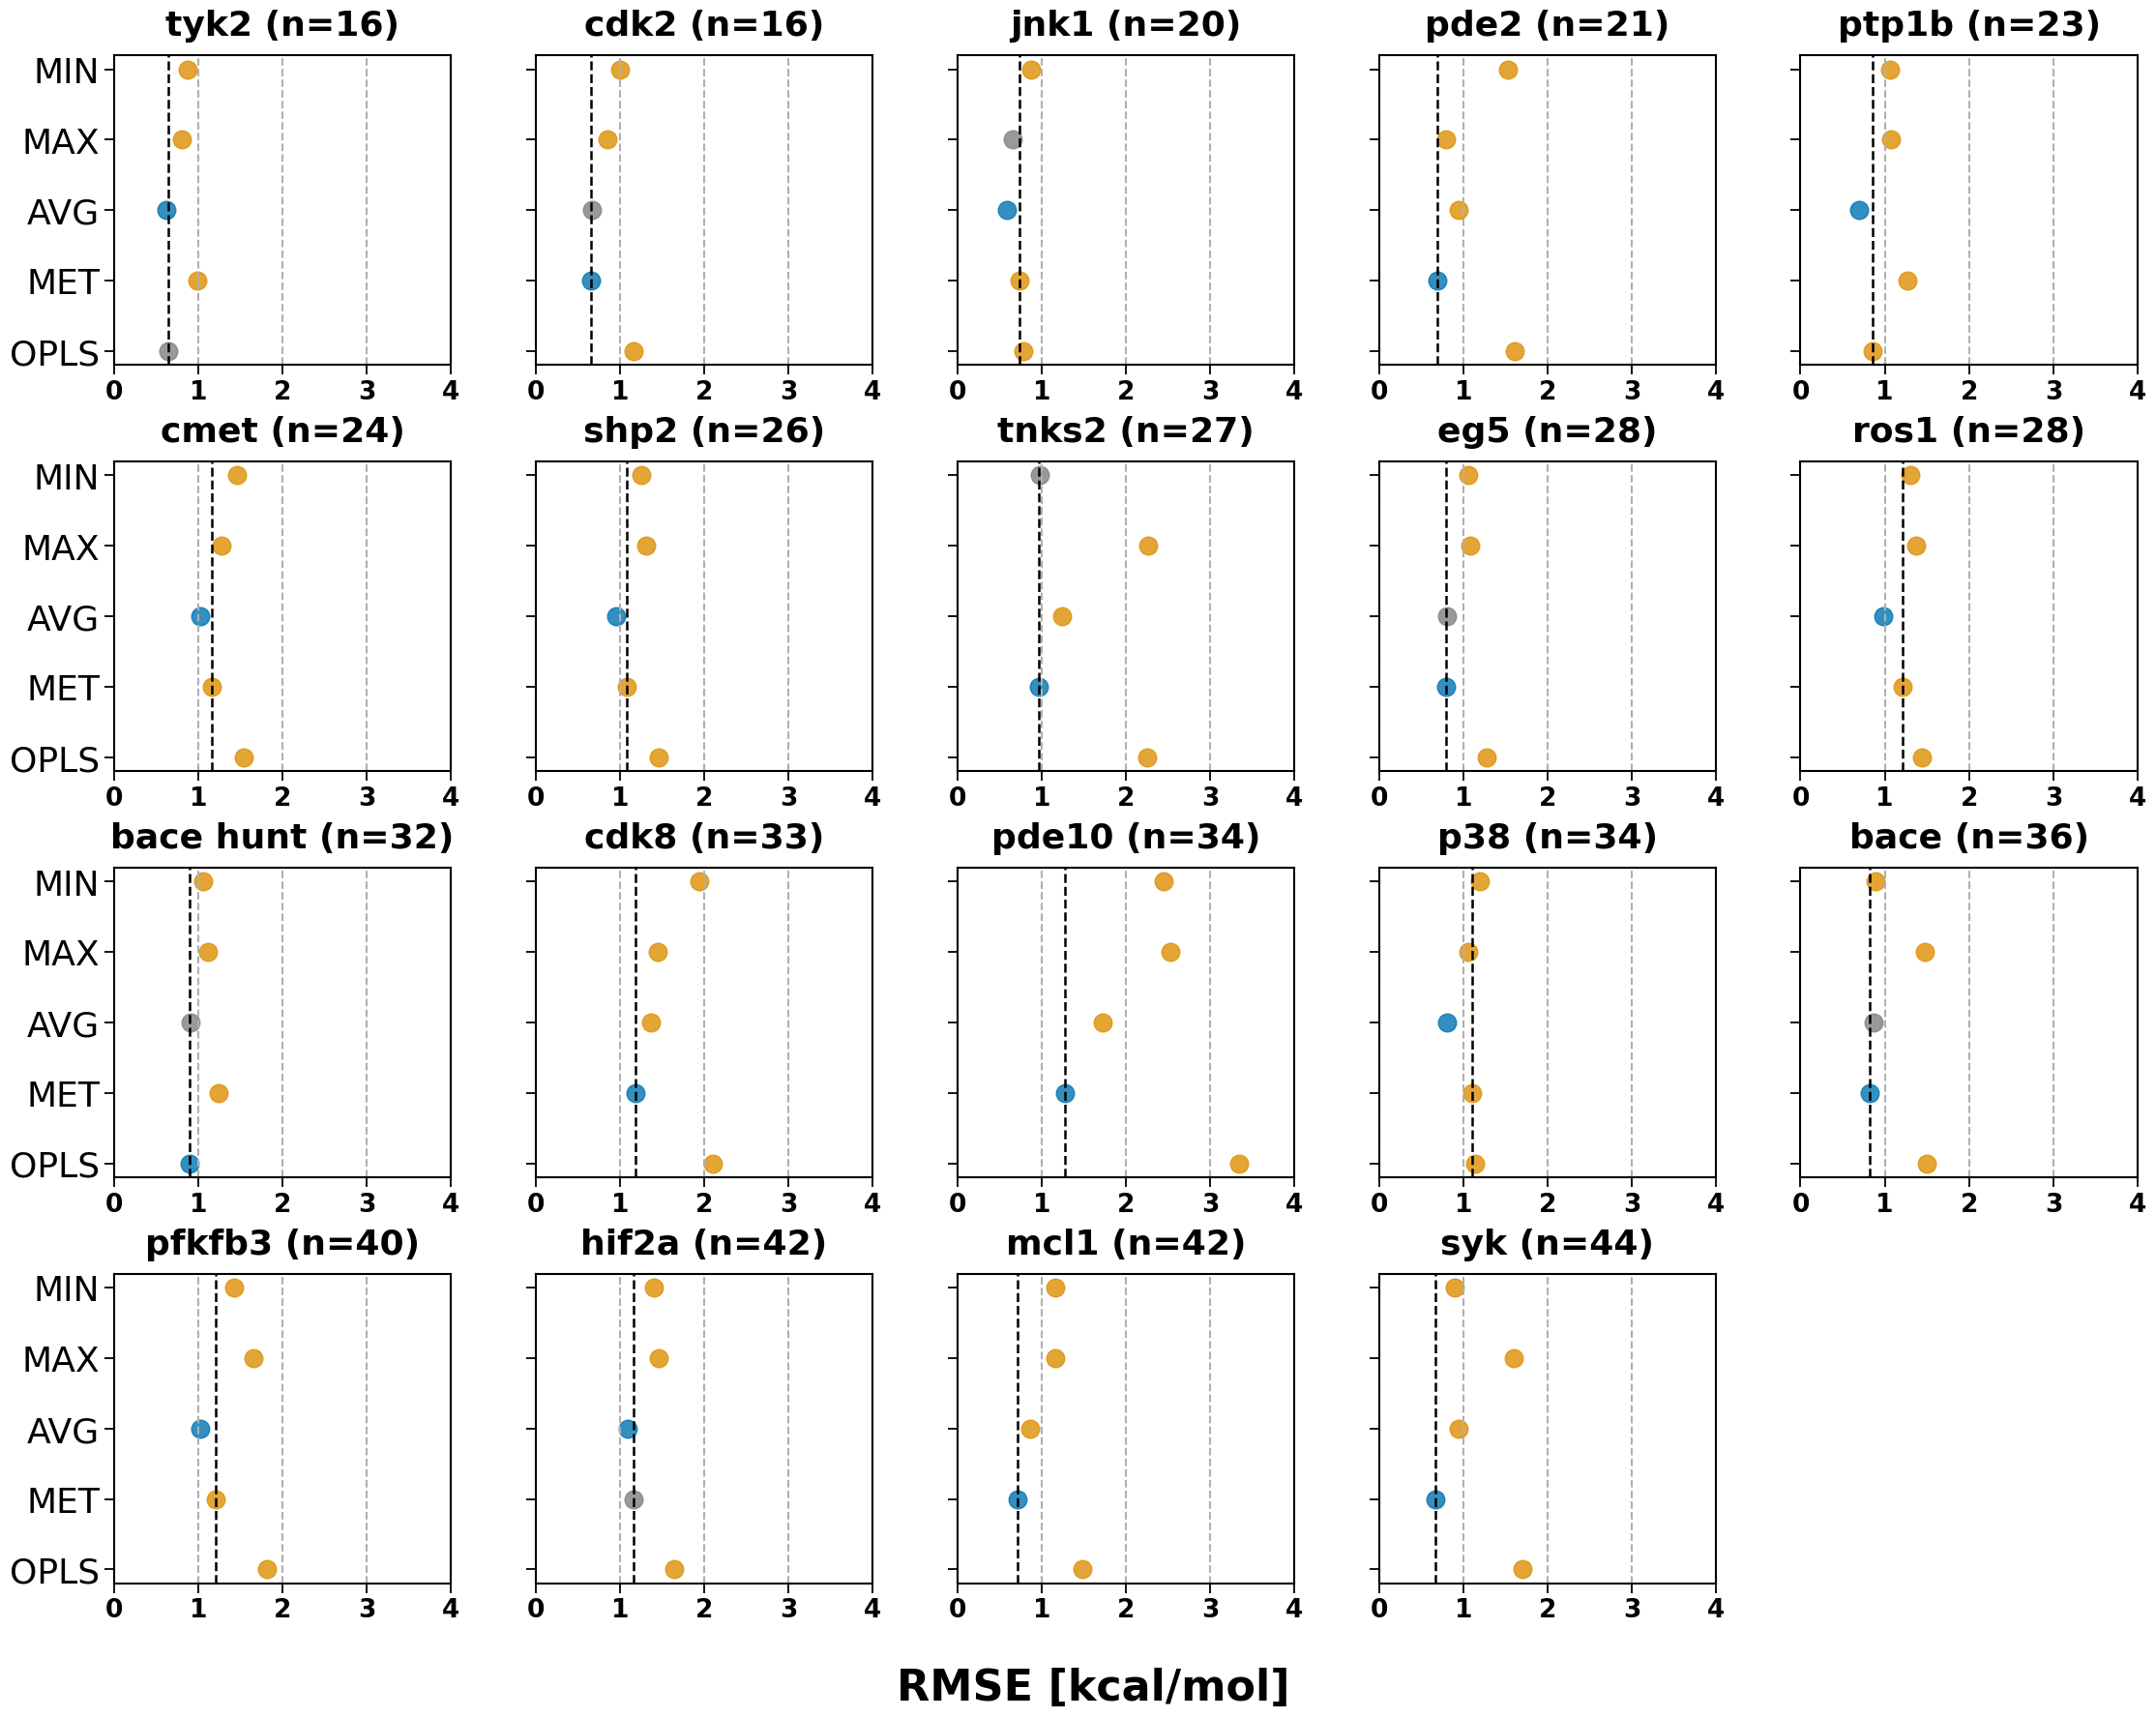


Effect-size counts for metric 'rmse':
- AVG: 0 targets → []
- MAX: 0 targets → []
- MET: 11 targets → ['cdk2', 'pde2', 'tnks2', 'eg5', 'cdk8', 'pde10', 'bace', 'pfkfb3', 'hif2a', 'mcl1', 'syk']
- MIN: 0 targets → []
- OPLS: 1 targets → ['ptp1b']


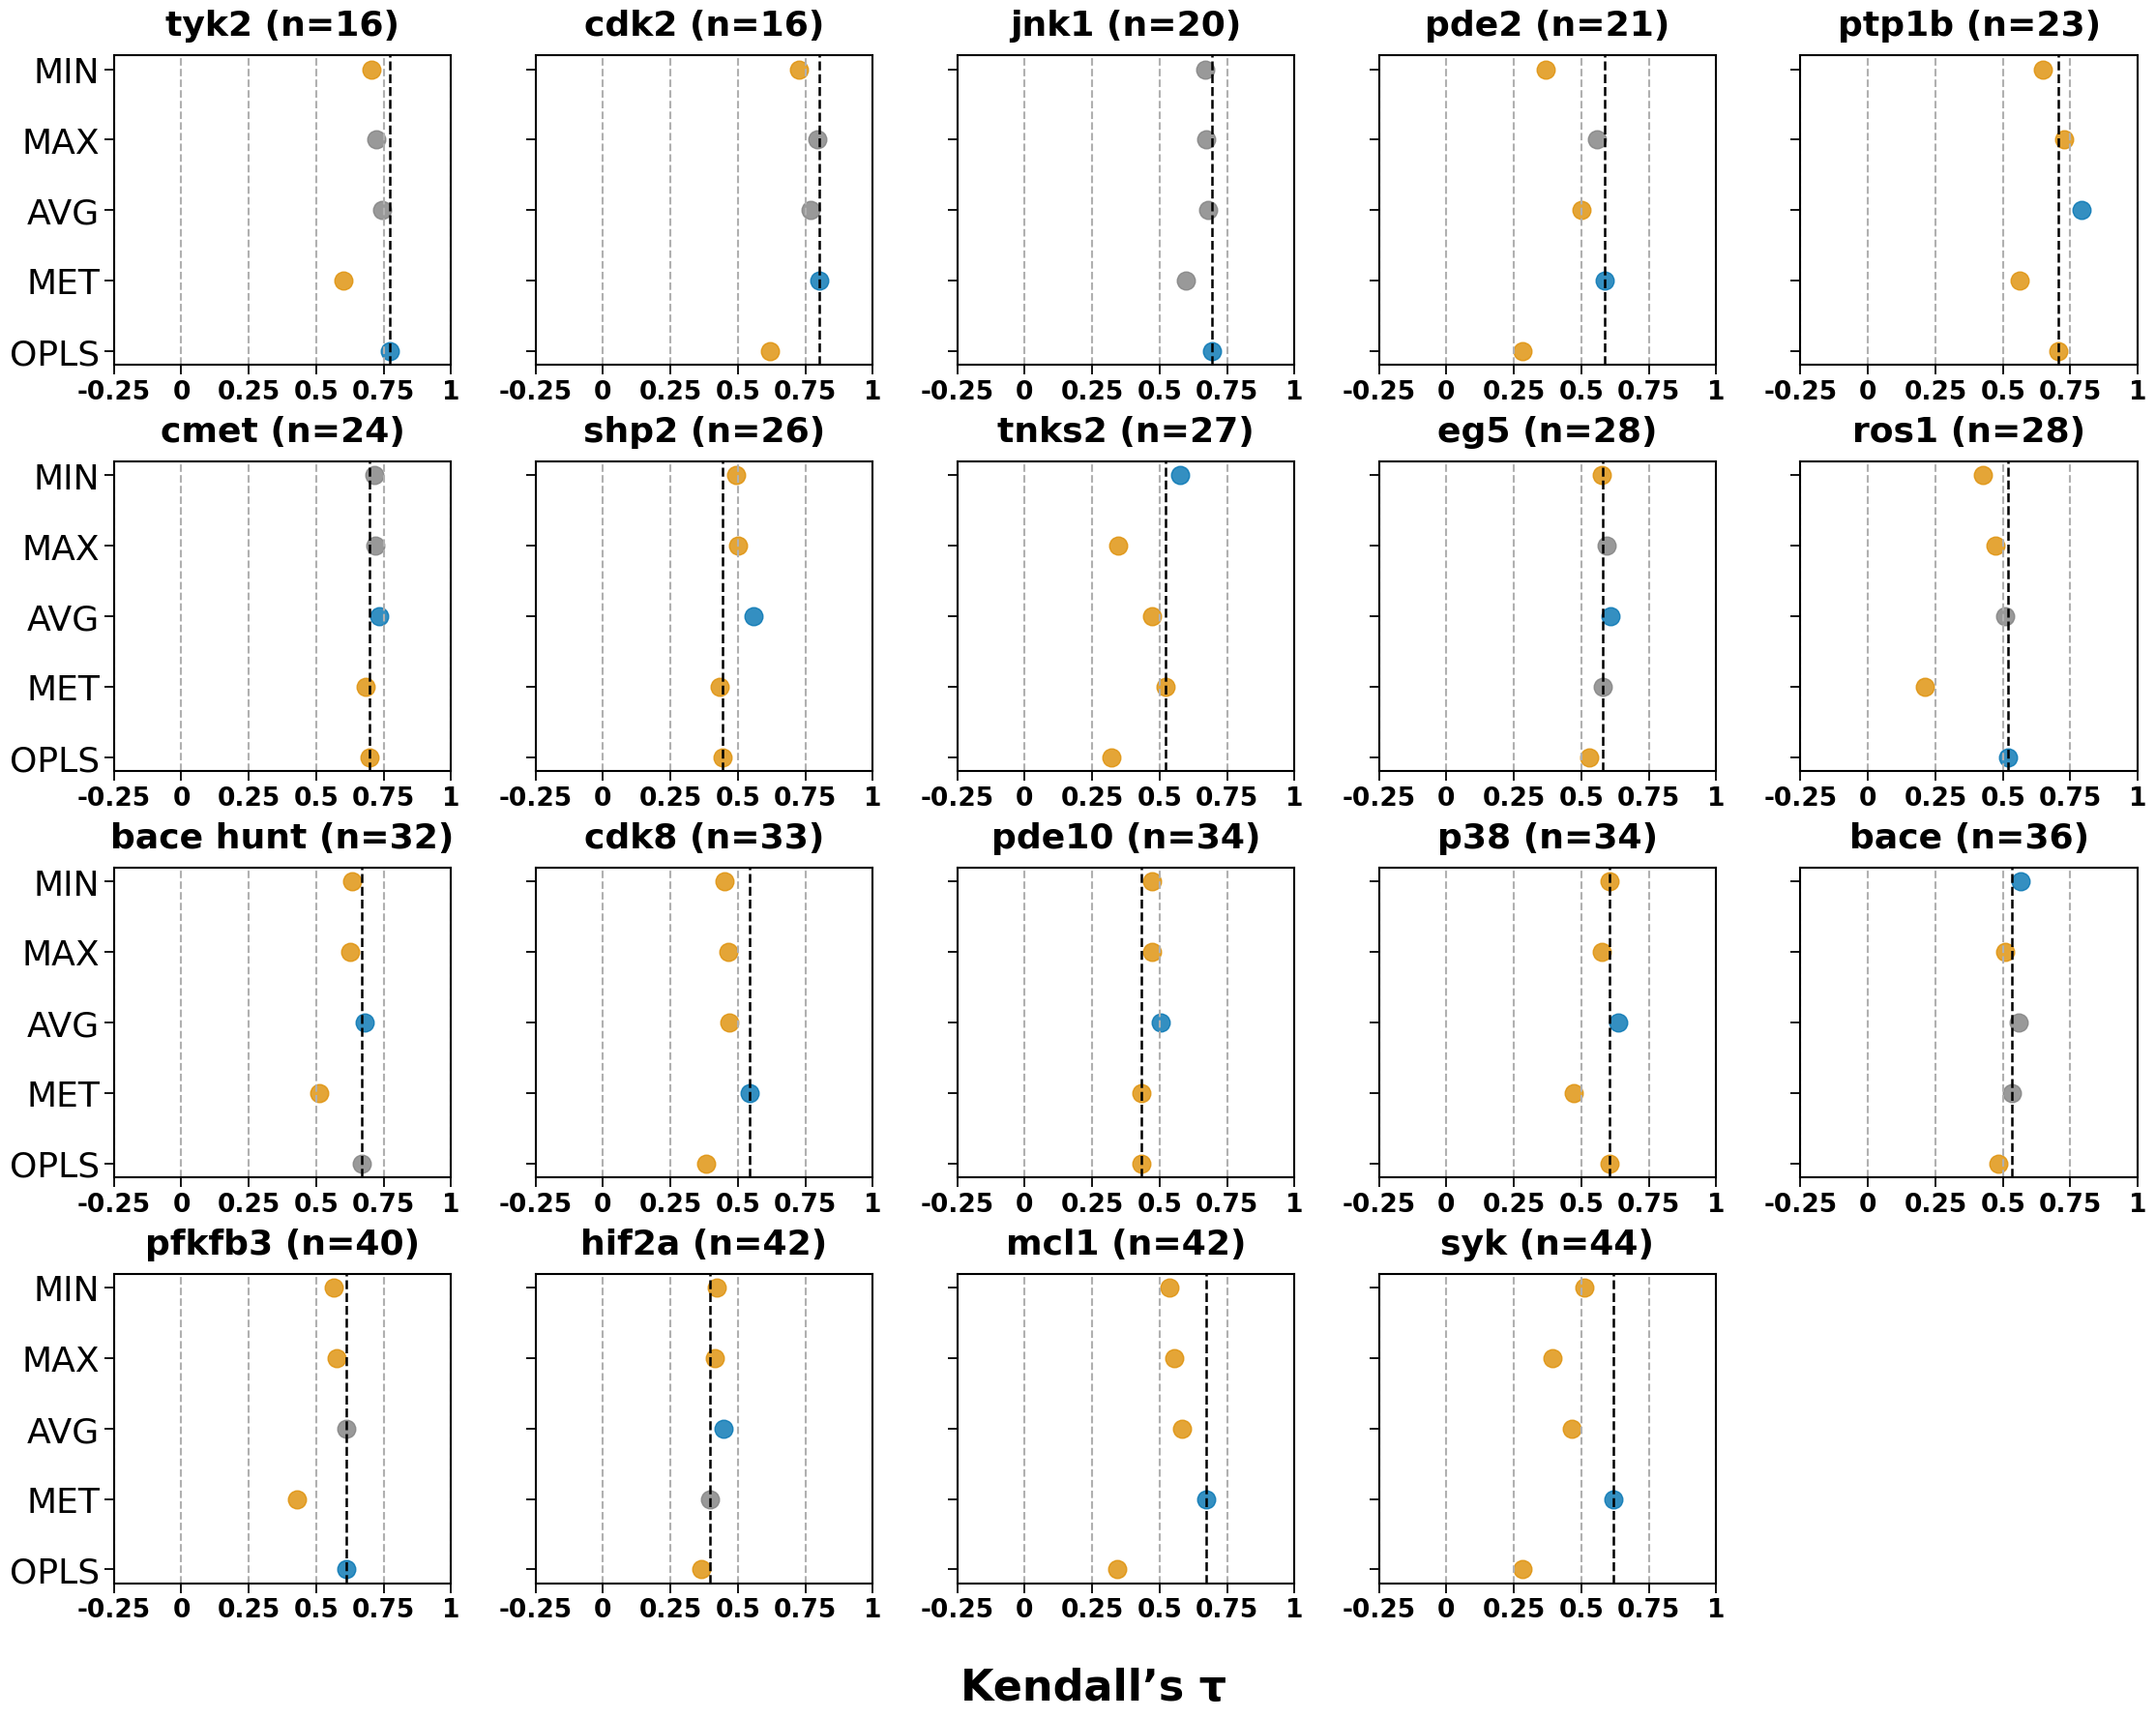


Effect-size counts for metric 'kendalls_tau':
- AVG: 0 targets → []
- MAX: 0 targets → []
- MET: 4 targets → ['pde2', 'tnks2', 'mcl1', 'syk']
- MIN: 0 targets → []
- OPLS: 1 targets → ['ros1']


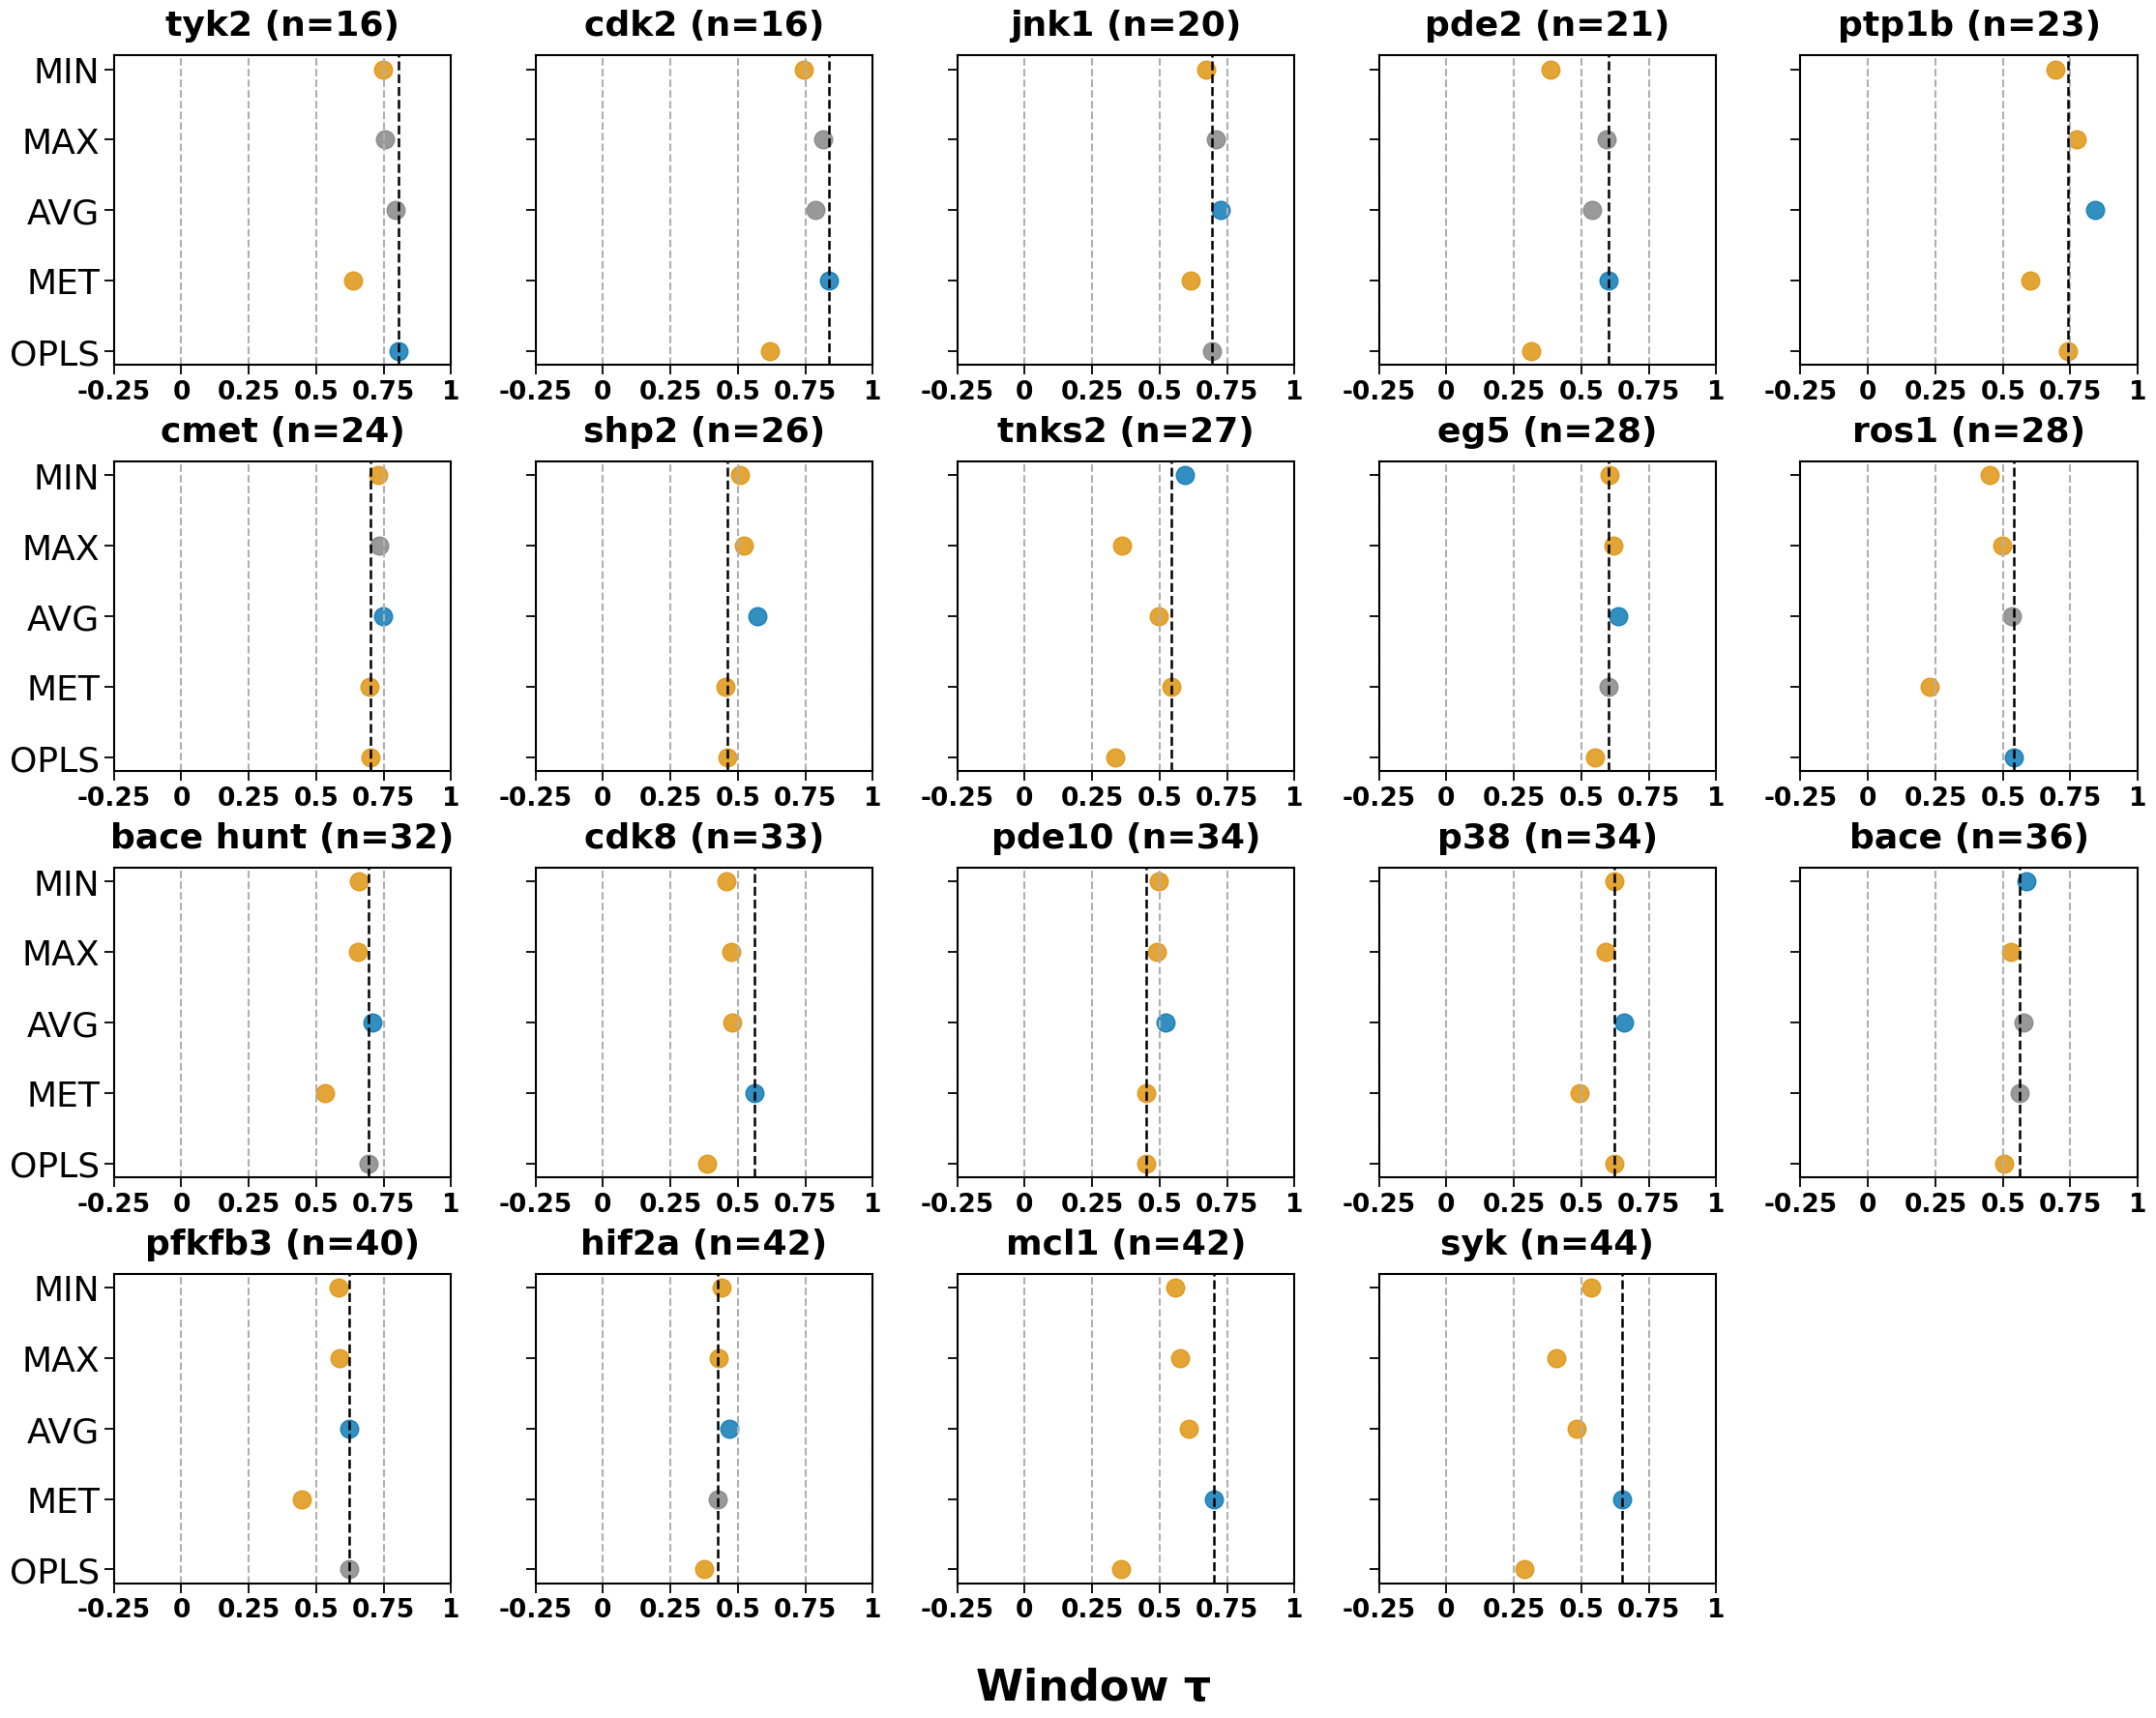


Effect-size counts for metric 'window_tau':
- AVG: 0 targets → []
- MAX: 0 targets → []
- MET: 5 targets → ['cdk2', 'pde2', 'tnks2', 'mcl1', 'syk']
- MIN: 0 targets → []
- OPLS: 1 targets → ['ros1']


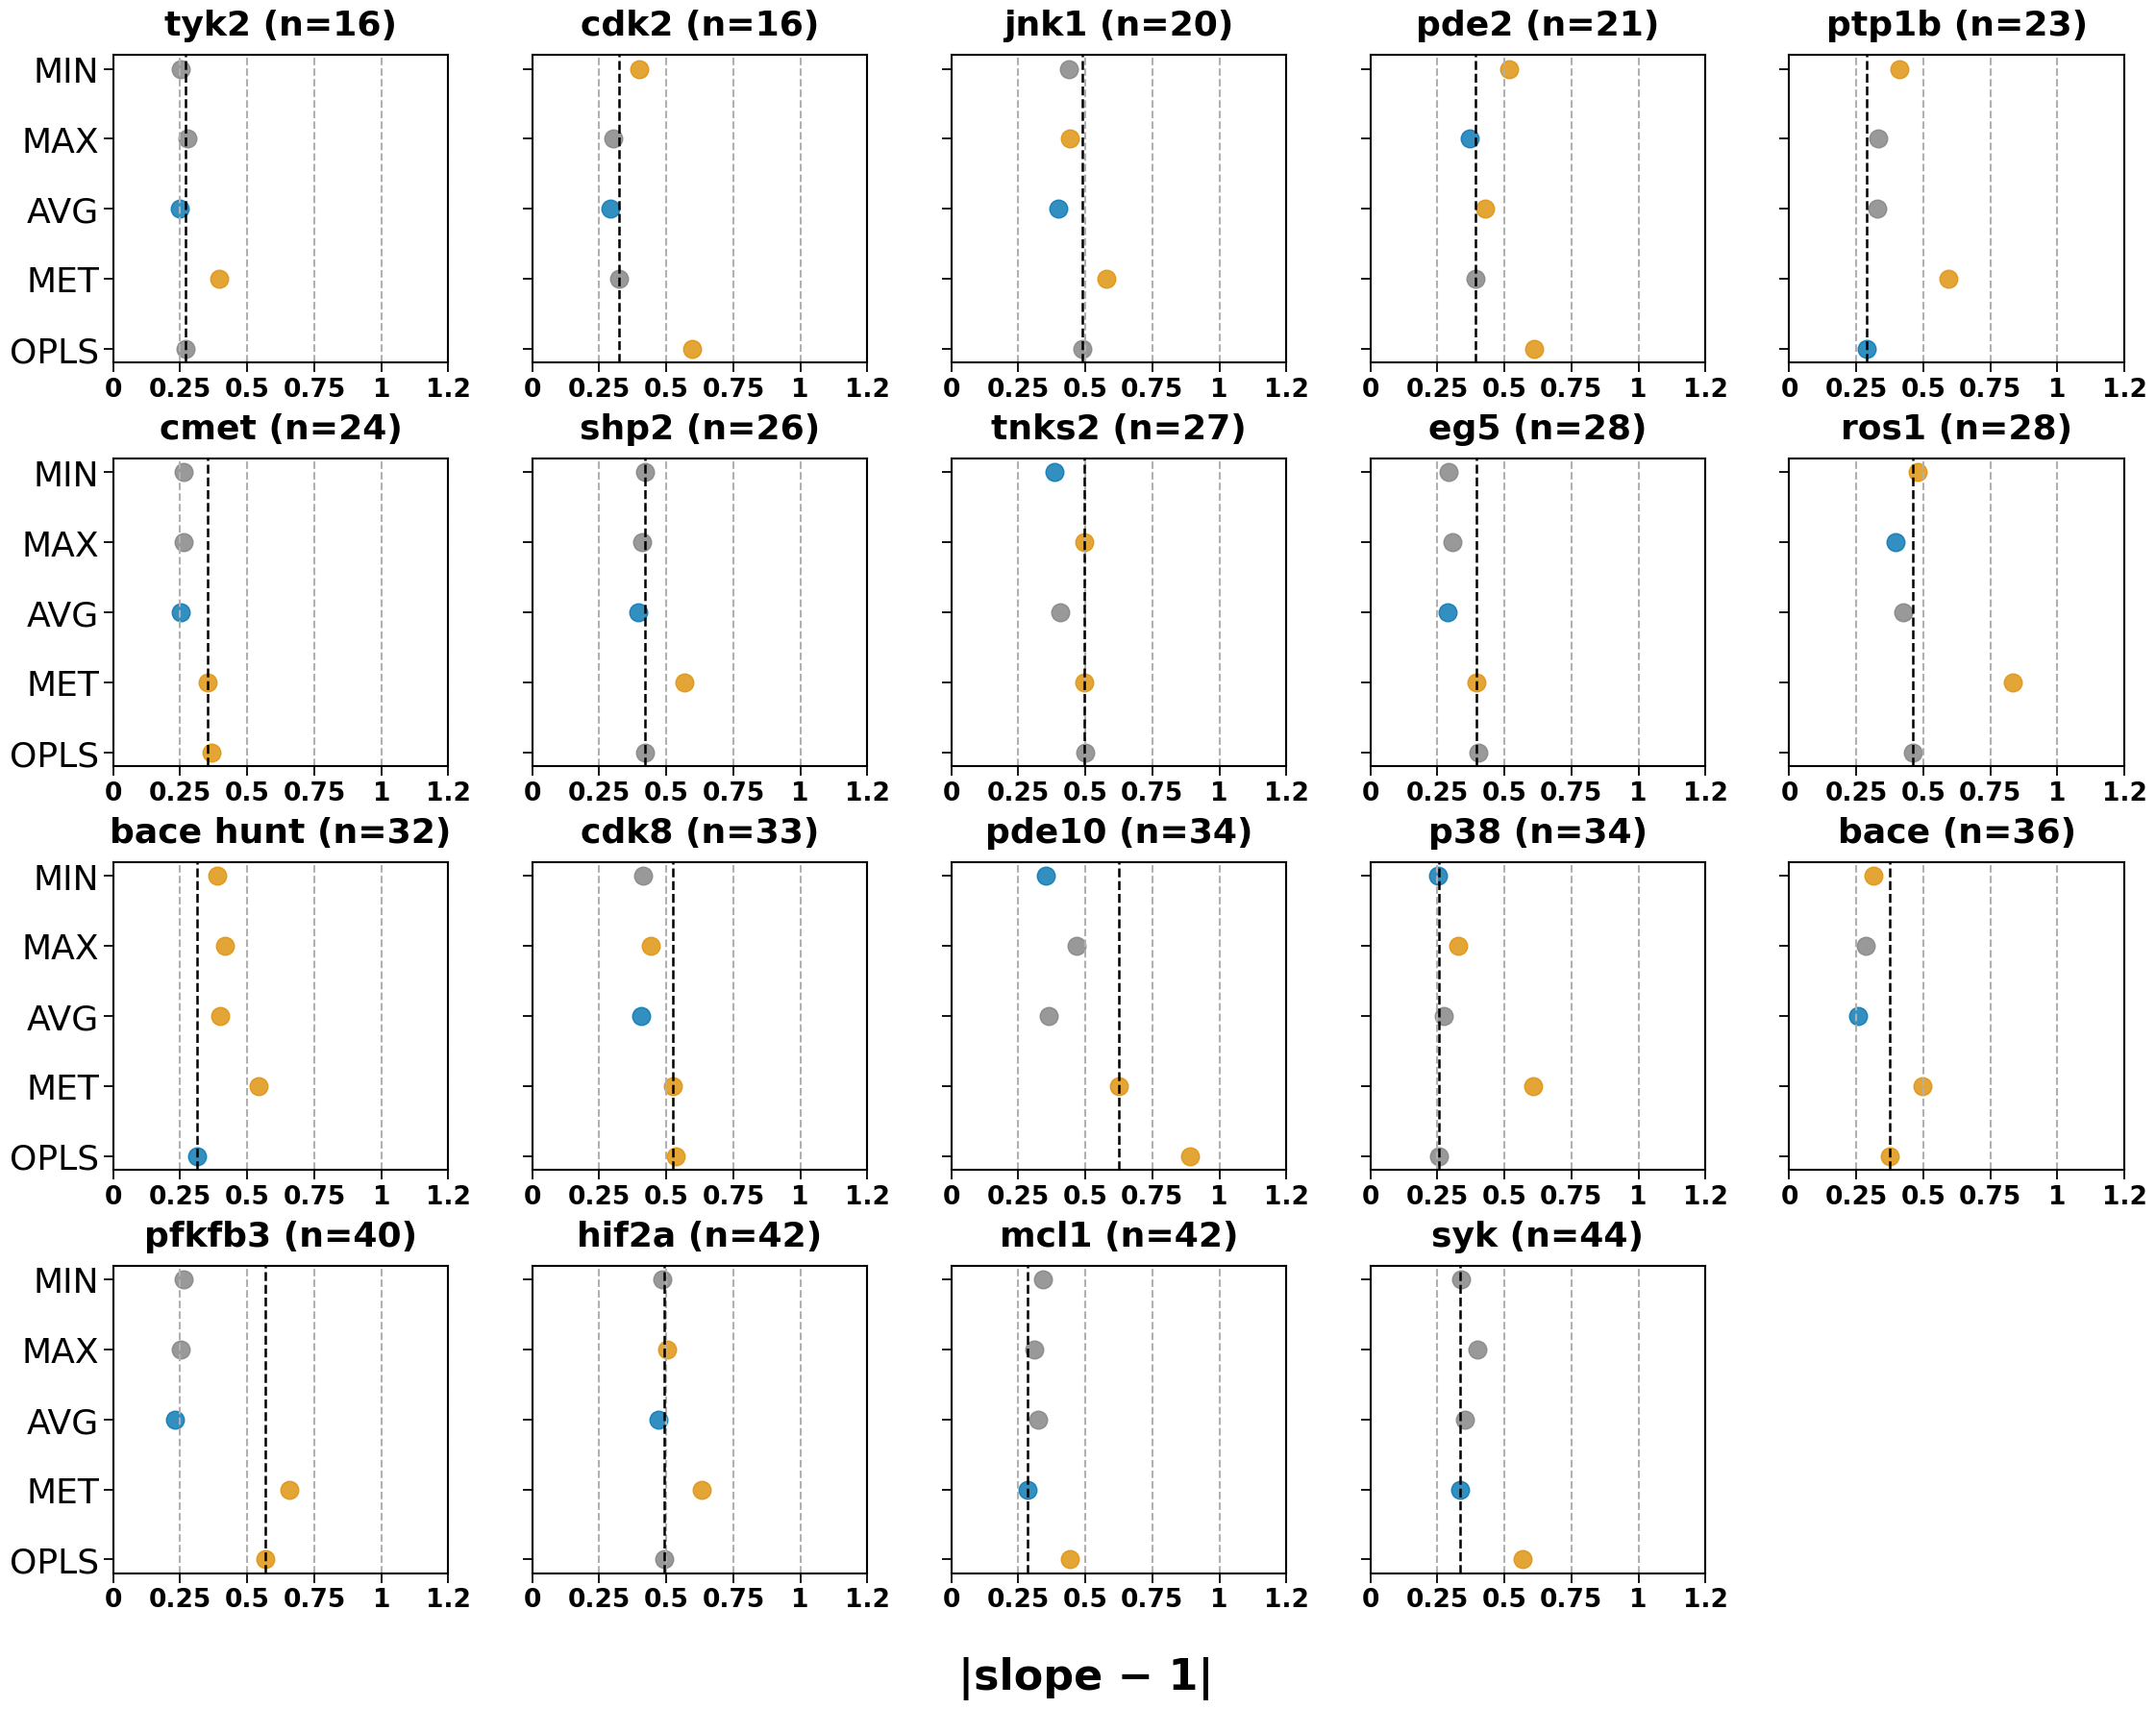


Effect-size counts for metric 'slope_diff':
- AVG: 0 targets → []
- MAX: 0 targets → []
- MET: 2 targets → ['cdk2', 'pde10']
- MIN: 0 targets → []
- OPLS: 3 targets → ['ptp1b', 'ros1', 'p38']


In [7]:
from DDG_ANALYSIS.E_EFFECT_SIZE_PLOT import plot_significance_ranks
plot_significance_ranks(results_all, DISPLAY_ORDER, ALPHA=ALPHA, METRICS=METRICS, target_counts_path="../../../0_DATA/N_COMPOUNDS_PER_TARGET.json", COUNT_EFFECTS=True, fusion=["MET","OPLS"], prefix="CONS_OPLS_")